# Corrigé · Quels rythmes d’éruption présenter aux visiteurs de Yellowstone ?

Le parc prépare un panneau sur le geyser Old Faithful. À partir de 272 éruptions observées, propose deux, trois ou quatre profils. Le panneau doit aider les visiteurs à comprendre le lien entre la durée d’une éruption et l’attente qui la suit.

Une ligne du fichier correspond à une éruption. `eruptions` est sa durée en minutes et `waiting` le temps en minutes jusqu’à la suivante. Tu disposes des observations et tu vas construire les groupes toi-même. [Documentation du jeu de données](https://search.r-project.org/R/refmans/datasets/html/faithful.html) · [CSV source](https://vincentarelbundock.github.io/Rdatasets/csv/datasets/faithful.csv)

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

dossier_data = next(d for d in (Path("data"), Path("../data"), Path("../../data")) if d.is_dir())
releves = pd.read_csv(dossier_data / "faithful.csv")
releves.head()

,eruptions,waiting
0,3.600,79
1,1.800,54
2,3.333,74
3,2.283,62
4,4.533,85


## 1. Lire le nuage de points

Trace un point par éruption, avec la durée sur l’axe horizontal et l’attente sur l’axe vertical. Que représente un point en haut à droite ? Avant de lancer K-means, note combien de profils tu distingues et décris-les en minutes, même approximativement.

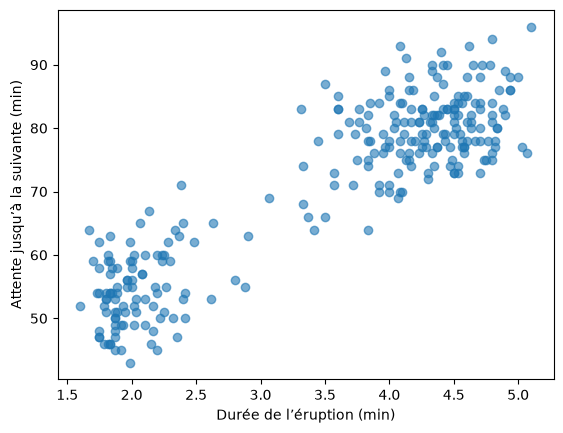

In [2]:
plt.scatter(releves["eruptions"], releves["waiting"], alpha=0.6)
plt.xlabel("Durée de l’éruption (min)")
plt.ylabel("Attente jusqu’à la suivante (min)")
plt.show()

En haut à droite, une longue éruption est suivie d’une longue attente. Deux concentrations se voient à l’œil. La première se situe autour de 2 minutes d’éruption et 55 minutes d’attente, la seconde autour de 4 à 4,5 minutes et 80 minutes d’attente.

## 2. Préparer les distances et former deux groupes

Relève le minimum et le maximum de chaque colonne. Même si les deux mesures sont exprimées en minutes, laquelle risque de peser le plus dans le calcul des distances ?

Sélectionne les deux colonnes et assemble `StandardScaler()` et `KMeans(n_clusters=2, n_init=10, random_state=42)` avec `make_pipeline`. Applique `fit_predict` et affiche le numéro de groupe des cinq premières éruptions. Que signifie ce numéro ?

In [3]:
mesures = releves[["eruptions", "waiting"]]
print(mesures.agg(["min", "max"]))

def construire_modele(k):
    return make_pipeline(
        StandardScaler(), KMeans(n_clusters=k, n_init=10, random_state=42)
    )

modele = construire_modele(2)
groupes = modele.fit_predict(mesures)
print("Groupes des cinq premières éruptions :", groupes[:5])

     eruptions  waiting
min        1.6       43
max        5.1       96


Groupes des cinq premières éruptions : [0 1 0 1 0]


Les durées vont de 1,6 à 5,1 minutes, les attentes de 43 à 96 minutes. Un écart de 10 minutes sur l’attente dépasse déjà toute l’étendue des durées. La standardisation exprime chaque écart en unités d’écart-type avant de calculer les distances. Chaque numéro désigne le centre le plus proche de l’éruption sur ces deux axes standardisés. Les numéros servent uniquement à repérer les groupes d’un essai.

## 3. Comparer deux, trois et quatre profils

Pour chaque valeur de `k`, refais le regroupement sur les mêmes mesures. Rattache les numéros aux relevés d’origine avec `assign`. Utilise `groupby` pour obtenir l’effectif, la durée moyenne et l’attente moyenne de chaque groupe **en minutes**.

Relève l’inertie avec `modele[-1].inertia_` et calcule sa baisse à chaque passage. Reprends le nuage avec une couleur par groupe. Quel profil se divise surtout au passage à trois groupes ? Et au passage à quatre ? Compare les moyennes et les positions sur le graphique pour retrouver les profils d’un essai à l’autre.

k = 2 | inertie = 79.58
        effectif  duree_moyenne  attente_moyenne
groupe                                          
1             98           2.05            54.59
0            174           4.30            80.08



k = 3 | inertie = 56.31
        effectif  duree_moyenne  attente_moyenne
groupe                                          
1             97           2.04            54.49
0             79           4.05            75.34
2             96           4.49            83.81



k = 4 | inertie = 43.87
        effectif  duree_moyenne  attente_moyenne
groupe                                          
0             57           1.98            50.49
3             40           2.13            60.20
1             79           4.05            75.34
2             96           4.49            83.81



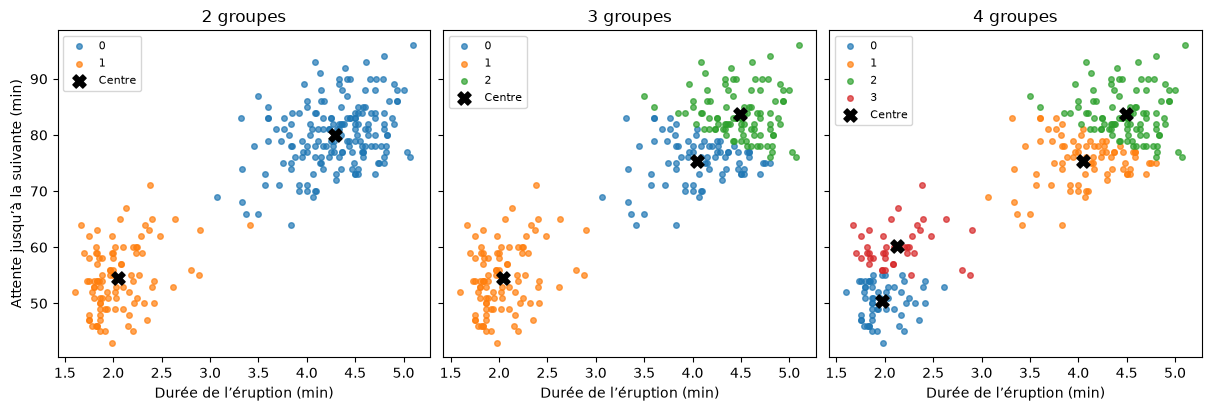

De 2 à 3 groupes : baisse de 23.26
De 3 à 4 groupes : baisse de 12.44


In [4]:
inerties = {}
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharex=True, sharey=True, layout="constrained")

for k, ax in zip([2, 3, 4], axes):
    modele = construire_modele(k)
    classement = releves.assign(groupe=modele.fit_predict(mesures))
    profils = classement.groupby("groupe").agg(
        effectif=("eruptions", "size"),
        duree_moyenne=("eruptions", "mean"),
        attente_moyenne=("waiting", "mean"),
    ).sort_values("duree_moyenne")
    inerties[k] = modele[-1].inertia_
    print(f"k = {k} | inertie = {inerties[k]:.2f}")
    print(profils.round(2), end="\n\n")

    for groupe, points in classement.groupby("groupe"):
        ax.scatter(points["eruptions"], points["waiting"], s=16, alpha=0.7, label=str(groupe))
    ax.scatter(profils["duree_moyenne"], profils["attente_moyenne"],
               marker="X", s=90, color="black", label="Centre")
    ax.set_title(f"{k} groupes")
    ax.set_xlabel("Durée de l’éruption (min)")
    ax.legend(fontsize=8)

axes[0].set_ylabel("Attente jusqu’à la suivante (min)")
plt.show()

for k in [3, 4]:
    print(f"De {k-1} à {k} groupes : baisse de {inerties[k-1] - inerties[k]:.2f}")

L’inertie passe de **79,58 à 56,31**, puis à **43,87**. Le troisième centre réduit surtout les distances parmi les éruptions longues. On y distingue des attentes moyennes de 75 et 84 minutes, tandis que le profil court garde une attente moyenne proche de 55 minutes. Le quatrième centre partage à son tour les éruptions courtes, avec des attentes moyennes de 50 et 60 minutes. Un centre supplémentaire permet de rapprocher les points de leur centre. Pour le panneau, il faut aussi décider si la distinction ainsi obtenue vaut la peine d’être expliquée.

## 4. Rédiger le panneau

Choisis le nombre de profils à présenter. Justifie ton choix avec un élément du graphique et un chiffre tiré de la comparaison. Écris ensuite **deux phrases pour les visiteurs**, en donnant les durées et les attentes en minutes.

**Choix pour le parc.** Je retiens deux profils. Les deux concentrations sont visibles dès le premier graphique. Un troisième groupe fait baisser l’inertie de 23,26, mais il oblige à expliquer une différence de 9 minutes d’attente entre deux profils d’éruptions longues. Pour une première lecture du phénomène, je garderais la distinction entre les éruptions courtes et longues.

**Texte du panneau**

> Parmi les éruptions observées, les 98 éruptions du groupe court duraient en moyenne 2 minutes et étaient suivies d’environ 55 minutes d’attente. Les 174 éruptions du groupe long duraient en moyenne 4,3 minutes, avec une attente moyenne de 80 minutes avant la suivante.